### NLP Assignment 3 : Transformers + RAG

---


Name: Shilok Kumar
Roll : 23I-2502



---


Stage 1 : Data Processing

---



In [1]:
from google.colab import drive
drive.mount('/content/drive')
print('Drive mounted.')

Mounted at /content/drive
Drive mounted.


In [2]:
import os

DATASET_DIR = '/content/drive/MyDrive/Dataset/Dataset'
OUTPUT_DIR  = '/content/drive/MyDrive/NLP_A3'

RESULTS_DIR = os.path.join(OUTPUT_DIR, 'results')
MODELS_DIR  = os.path.join(OUTPUT_DIR, 'models')
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR,  exist_ok=True)

# ── Hyper-parameters for Data Processing ──────────────────────────────────
SAMPLES_PER_CATEGORY = 12_000   # 3 × 12,000 = 36,000 total
MAX_SEQ_LEN   = 128
MIN_WORD_FREQ = 2
PAD_TOKEN, UNK_TOKEN = '<PAD>', '<UNK>'
TRAIN_RATIO, VAL_RATIO = 0.70, 0.15
CATEGORIES = {
    'cellphones':  'cellphones.json.gz',
    'electronics': 'electronics.json.gz',
    'sports':      'sports.json.gz',
}
CATEGORY_TO_IDX = {'cellphones': 0, 'electronics': 1, 'sports': 2}
IDX_TO_CATEGORY = {v: k for k, v in CATEGORY_TO_IDX.items()}

RANDOM_SEED = 42

print('Constants set.')
print(f'  Samples per category : {SAMPLES_PER_CATEGORY:,}')
print(f'  Target total         : {SAMPLES_PER_CATEGORY * len(CATEGORIES):,}')
print(f'  Max sequence length  : {MAX_SEQ_LEN}')
print(f'  Results dir          : {RESULTS_DIR}')

Constants set.
  Samples per category : 12,000
  Target total         : 36,000
  Max sequence length  : 128
  Results dir          : /content/drive/MyDrive/NLP_A3/results


In [3]:
import gzip
import json
import re
import random
import pickle
import numpy as np
from collections import Counter

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print('Imports complete.')

Imports complete.


In [4]:
def load_category(filepath, category_name, n_samples, seed=42):
    """
    Reads a gzipped JSON-lines Amazon Reviews file.
    Keeps only records that have both 'reviewText' and 'overall'.
    Draws a reproducible random sample of n_samples.
    """
    records = []
    with gzip.open(filepath, 'rt', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                obj = json.loads(line)
            except json.JSONDecodeError:
                continue
            text   = obj.get('reviewText', '').strip()
            rating = obj.get('overall', None)
            if text and rating is not None:
                records.append({
                    'text'    : text,
                    'rating'  : int(rating),
                    'category': category_name,
                })

    rng = random.Random(seed)
    if len(records) > n_samples:
        records = rng.sample(records, n_samples)

    print(f'  [{category_name:<12}] available: {len(records):>6,} (requested {n_samples:,})')
    return records


all_records = []
for cat_name, fname in CATEGORIES.items():
    fpath = os.path.join(DATASET_DIR, fname)
    recs  = load_category(fpath, cat_name, SAMPLES_PER_CATEGORY, seed=RANDOM_SEED)
    all_records.extend(recs)

print(f'\nTotal records loaded: {len(all_records):,}')

  [cellphones  ] available: 12,000 (requested 12,000)
  [electronics ] available: 12,000 (requested 12,000)
  [sports      ] available: 12,000 (requested 12,000)

Total records loaded: 36,000


In [5]:
from pprint import pprint

print("\nSample records:")
pprint(all_records[:1])


Sample records:
[{'category': 'cellphones',
  'rating': 5,
  'text': 'Fits the phone great, not as bulky as I was expecting. Great '
          'material, would recommend this to anyone with a note 3'}]


In [6]:
def rating_to_sentiment(rating: int) -> int:
    """Maps star rating (1-5) to 3-class sentiment index."""
    if rating <= 2:
        return 0   # Negative
    elif rating == 3:
        return 1   # Neutral
    else:
        return 2   # Positive


for rec in all_records:
    rec['sentiment']    = rating_to_sentiment(rec['rating'])
    rec['category_idx'] = CATEGORY_TO_IDX[rec['category']]

# Distribution check
sent_dist = Counter(rec['sentiment']    for rec in all_records)
cat_dist  = Counter(rec['category']     for rec in all_records)

SENTIMENT_NAMES = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
print('Sentiment distribution:')
for idx, name in SENTIMENT_NAMES.items():
    print(f'  {name:<10}: {sent_dist[idx]:>6,} ({sent_dist[idx]/len(all_records)*100:.1f}%)')

print('\nCategory distribution:')
for cat, idx in CATEGORY_TO_IDX.items():
    print(f'  {cat:<14}: {cat_dist[cat]:>6,}')

Sentiment distribution:
  Negative  :  3,577 (9.9%)
  Neutral   :  3,328 (9.2%)
  Positive  : 29,095 (80.8%)

Category distribution:
  cellphones    : 12,000
  electronics   : 12,000
  sports        : 12,000


In [7]:
from pprint import pprint

print("\nSample records:")
pprint(all_records[:1])


Sample records:
[{'category': 'cellphones',
  'category_idx': 0,
  'rating': 5,
  'sentiment': 2,
  'text': 'Fits the phone great, not as bulky as I was expecting. Great '
          'material, would recommend this to anyone with a note 3'}]


In [8]:
random.shuffle(all_records)

n       = len(all_records)
n_train = int(n * TRAIN_RATIO)
n_val   = int(n * VAL_RATIO)

train_data = all_records[:n_train]
val_data   = all_records[n_train : n_train + n_val]
test_data  = all_records[n_train + n_val :]

print(f'Train : {len(train_data):,}  ({len(train_data)/n*100:.1f}%)')
print(f'Val   : {len(val_data):,}  ({len(val_data)/n*100:.1f}%)')
print(f'Test  : {len(test_data):,}  ({len(test_data)/n*100:.1f}%)')
print(f'Total : {len(train_data)+len(val_data)+len(test_data):,}')

Train : 25,200  (70.0%)
Val   : 5,400  (15.0%)
Test  : 5,400  (15.0%)
Total : 36,000


In [9]:
_HTML_TAG  = re.compile(r'<[^>]+>')
_URL       = re.compile(r'https?://\S+|www\.\S+')
_NON_ALPHA = re.compile(r"[^a-z\s']")
_MULTI_SPC = re.compile(r'\s+')

def clean_text(text: str) -> str:
    """
    Applies the following cleaning steps in order:
      1. Lowercase
      2. Strip HTML tags
      3. Remove URLs
      4. Remove non-alphabetic characters (apostrophes kept for contractions)
      5. Collapse multiple whitespace to single space
      6. Strip leading/trailing whitespace
    """
    text = text.lower()
    text = _HTML_TAG.sub(' ', text)
    text = _URL.sub(' ', text)
    text = _NON_ALPHA.sub(' ', text)
    text = _MULTI_SPC.sub(' ', text)
    return text.strip()


for rec in train_data: rec['clean_text'] = clean_text(rec['text'])
for rec in val_data:   rec['clean_text'] = clean_text(rec['text'])
for rec in test_data:  rec['clean_text'] = clean_text(rec['text'])

# Spot-check
sample = train_data[0]
print('--- Cleaning spot-check ---')
print(f'Original : {sample["text"][:200]}')
print(f'Cleaned  : {sample["clean_text"][:200]}')

--- Cleaning spot-check ---
Original : Really happy with this case for my Nexus 5. Really well made fits perfect and protect the phone really well.
Cleaned  : really happy with this case for my nexus really well made fits perfect and protect the phone really well


In [10]:
def tokenize(text: str):
    """Splits cleaned text on whitespace. No external library used."""
    return text.split()


for rec in train_data: rec['tokens'] = tokenize(rec['clean_text'])
for rec in val_data:   rec['tokens'] = tokenize(rec['clean_text'])
for rec in test_data:  rec['tokens'] = tokenize(rec['clean_text'])

# Length statistics (training set only)
lengths = [len(rec['tokens']) for rec in train_data]
print('Token-length statistics on training set:')
print(f'  Min    : {min(lengths)}')
print(f'  Max    : {max(lengths)}')
print(f'  Mean   : {np.mean(lengths):.1f}')
print(f'  Median : {np.median(lengths):.0f}')
print(f'  p95    : {np.percentile(lengths, 95):.0f}')
print(f'\n  MAX_SEQ_LEN = {MAX_SEQ_LEN} covers ~'
      f'{(np.array(lengths) <= MAX_SEQ_LEN).mean()*100:.1f}% of training reviews')

Token-length statistics on training set:
  Min    : 1
  Max    : 5634
  Mean   : 100.1
  Median : 55
  p95    : 327

  MAX_SEQ_LEN = 128 covers ~78.2% of training reviews


In [11]:
from pprint import pprint

print("\nSample records:")
pprint(all_records[:1])


Sample records:
[{'category': 'cellphones',
  'category_idx': 0,
  'clean_text': 'really happy with this case for my nexus really well made '
                'fits perfect and protect the phone really well',
  'rating': 5,
  'sentiment': 2,
  'text': 'Really happy with this case for my Nexus 5. Really well made fits '
          'perfect and protect the phone really well.',
  'tokens': ['really',
             'happy',
             'with',
             'this',
             'case',
             'for',
             'my',
             'nexus',
             'really',
             'well',
             'made',
             'fits',
             'perfect',
             'and',
             'protect',
             'the',
             'phone',
             'really',
             'well']}]


In [12]:
word_counts = Counter()
for rec in train_data:
    word_counts.update(rec['tokens'])

# Keep only words that appear at least MIN_WORD_FREQ times
vocab_words = [w for w, c in word_counts.items() if c >= MIN_WORD_FREQ]

# Special tokens first, then alphabetically sorted word list
vocab = [PAD_TOKEN, UNK_TOKEN] + sorted(vocab_words)

word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for w, i in word2idx.items()}

PAD_IDX = word2idx[PAD_TOKEN]   # 0
UNK_IDX = word2idx[UNK_TOKEN]   # 1

print(f'Unique tokens in training set        : {len(word_counts):,}')
print(f'Vocab size (freq ≥ {MIN_WORD_FREQ})           : {len(vocab):,}')
print(f'Tokens filtered out (rare)           : {len(word_counts) - len(vocab_words):,}')
print(f'PAD index : {PAD_IDX}')
print(f'UNK index : {UNK_IDX}')
print(f'Sample vocab entries: {vocab[2:12]}')

Unique tokens in training set        : 37,258
Vocab size (freq ≥ 2)           : 20,058
Tokens filtered out (rare)           : 17,202
PAD index : 0
UNK index : 1
Sample vocab entries: ["'", "''", "'a'", "'ac'", "'as", "'avoid", "'back'", "'basic'", "'battery", "'beats'"]


In [13]:
from pprint import pprint

print("\nSample records:")
pprint(all_records[:1])


Sample records:
[{'category': 'cellphones',
  'category_idx': 0,
  'clean_text': 'really happy with this case for my nexus really well made '
                'fits perfect and protect the phone really well',
  'rating': 5,
  'sentiment': 2,
  'text': 'Really happy with this case for my Nexus 5. Really well made fits '
          'perfect and protect the phone really well.',
  'tokens': ['really',
             'happy',
             'with',
             'this',
             'case',
             'for',
             'my',
             'nexus',
             'really',
             'well',
             'made',
             'fits',
             'perfect',
             'and',
             'protect',
             'the',
             'phone',
             'really',
             'well']}]


In [14]:
def encode_and_pad(tokens, word2idx, max_len, pad_idx, unk_idx):
    """
    Converts token list → fixed-length integer sequence.
      • Tokens beyond max_len are TRUNCATED (right-truncation).
      • Sequences shorter than max_len are RIGHT-PADDED with pad_idx.
    Returns a list of ints with length exactly max_len.
    """
    indices = [word2idx.get(t, unk_idx) for t in tokens[:max_len]]
    if len(indices) < max_len:
        indices += [pad_idx] * (max_len - len(indices))
    return indices


def process_split(split_data, word2idx, max_len, pad_idx, unk_idx):
    """Encodes an entire split into numpy arrays."""
    input_ids  = []
    sentiments = []
    cat_labels = []
    for rec in split_data:
        input_ids.append(encode_and_pad(rec['tokens'], word2idx, max_len, pad_idx, unk_idx))
        sentiments.append(rec['sentiment'])
        cat_labels.append(rec['category_idx'])
    return (
        np.array(input_ids,  dtype=np.int32),
        np.array(sentiments, dtype=np.int64),
        np.array(cat_labels, dtype=np.int64),
    )


X_train, y_sent_train, y_cat_train = process_split(train_data, word2idx, MAX_SEQ_LEN, PAD_IDX, UNK_IDX)
X_val,   y_sent_val,   y_cat_val   = process_split(val_data,   word2idx, MAX_SEQ_LEN, PAD_IDX, UNK_IDX)
X_test,  y_sent_test,  y_cat_test  = process_split(test_data,  word2idx, MAX_SEQ_LEN, PAD_IDX, UNK_IDX)

print('Array shapes:')
print(f'  X_train      : {X_train.shape}    y_sent_train : {y_sent_train.shape}    y_cat_train : {y_cat_train.shape}')
print(f'  X_val        : {X_val.shape}    y_sent_val   : {y_sent_val.shape}    y_cat_val   : {y_cat_val.shape}')
print(f'  X_test       : {X_test.shape}    y_sent_test  : {y_sent_test.shape}    y_cat_test  : {y_cat_test.shape}')

# Sanity check: first training example decoded
decoded = ' '.join(idx2word[i] for i in X_train[0] if i != PAD_IDX)
print(f'\nDecoded sample[0]: {decoded[:120]}...')

Array shapes:
  X_train      : (25200, 128)    y_sent_train : (25200,)    y_cat_train : (25200,)
  X_val        : (5400, 128)    y_sent_val   : (5400,)    y_cat_val   : (5400,)
  X_test       : (5400, 128)    y_sent_test  : (5400,)    y_cat_test  : (5400,)

Decoded sample[0]: really happy with this case for my nexus really well made fits perfect and protect the phone really well...


In [15]:
# Input sequences
np.save(os.path.join(RESULTS_DIR, 'X_train.npy'),       X_train)
np.save(os.path.join(RESULTS_DIR, 'X_val.npy'),         X_val)
np.save(os.path.join(RESULTS_DIR, 'X_test.npy'),        X_test)

# Task 1 labels — sentiment
np.save(os.path.join(RESULTS_DIR, 'y_sent_train.npy'),  y_sent_train)
np.save(os.path.join(RESULTS_DIR, 'y_sent_val.npy'),    y_sent_val)
np.save(os.path.join(RESULTS_DIR, 'y_sent_test.npy'),   y_sent_test)

# Task 2 labels — category
np.save(os.path.join(RESULTS_DIR, 'y_cat_train.npy'),   y_cat_train)
np.save(os.path.join(RESULTS_DIR, 'y_cat_val.npy'),     y_cat_val)
np.save(os.path.join(RESULTS_DIR, 'y_cat_test.npy'),    y_cat_test)

# Vocabulary
vocab_data = {
    'word2idx'    : word2idx,
    'idx2word'    : idx2word,
    'vocab_size'  : len(vocab),
    'pad_idx'     : PAD_IDX,
    'unk_idx'     : UNK_IDX,
    'max_seq_len' : MAX_SEQ_LEN,
}
with open(os.path.join(RESULTS_DIR, 'vocab.pkl'), 'wb') as f:
    pickle.dump(vocab_data, f)

# Config summary
config = {
    'samples_per_category': SAMPLES_PER_CATEGORY,
    'total_samples'        : len(all_records),
    'max_seq_len'          : MAX_SEQ_LEN,
    'min_word_freq'        : MIN_WORD_FREQ,
    'vocab_size'           : len(vocab),
    'train_size'           : len(train_data),
    'val_size'             : len(val_data),
    'test_size'            : len(test_data),
    'categories'           : list(CATEGORIES.keys()),
    'sentiment_map'        : {0: 'Negative', 1: 'Neutral', 2: 'Positive'},
    'category_map'         : IDX_TO_CATEGORY,
    'random_seed'          : RANDOM_SEED,
}
import json as _json
with open(os.path.join(RESULTS_DIR, 'data_config.json'), 'w') as f:
    _json.dump(config, f, indent=2)

print('Saved to:', RESULTS_DIR)
print('Files:', sorted(os.listdir(RESULTS_DIR)))

Saved to: /content/drive/MyDrive/NLP_A3/results
Files: ['X_test.npy', 'X_train.npy', 'X_val.npy', 'data_config.json', 'encoder_learning_curves.png', 'train_embeddings.npy', 'train_texts.json', 'vocab.pkl', 'y_cat_test.npy', 'y_cat_train.npy', 'y_cat_val.npy', 'y_sent_test.npy', 'y_sent_train.npy', 'y_sent_val.npy']


In [16]:
print('=' * 55)
print('  DATA PROCESSING ')
print('=' * 55)
print(f'  Categories      : Cellphones, Electronics, Sports')
print(f'  Total samples   : {len(all_records):,}')
print(f'  Train / Val / Test: {len(train_data):,} / {len(val_data):,} / {len(test_data):,}')
print(f'  Vocabulary size : {len(vocab):,}')
print(f'  Max seq length  : {MAX_SEQ_LEN}')
print(f'  Task 1 labels   : Sentiment (Negative=0, Neutral=1, Positive=2)')
print(f'  Task 2 labels   : Category  (Cellphones=0, Electronics=1, Sports=2)')
print('=' * 55)

  DATA PROCESSING 
  Categories      : Cellphones, Electronics, Sports
  Total samples   : 36,000
  Train / Val / Test: 25,200 / 5,400 / 5,400
  Vocabulary size : 20,058
  Max seq length  : 128
  Task 1 labels   : Sentiment (Negative=0, Neutral=1, Positive=2)
  Task 2 labels   : Category  (Cellphones=0, Electronics=1, Sports=2)




---


**Part** A : Encoder Model


---



In [17]:
import torch, math, pickle
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np, os, json as _json
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {device}')
if device.type == 'cuda':
    print(f'  GPU  : {torch.cuda.get_device_name(0)}')
    print(f'  VRAM : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')

def _load(name): return np.load(os.path.join(RESULTS_DIR, name))
X_train      = _load('X_train.npy');      X_val  = _load('X_val.npy');  X_test  = _load('X_test.npy')
y_sent_train = _load('y_sent_train.npy'); y_sent_val = _load('y_sent_val.npy'); y_sent_test = _load('y_sent_test.npy')
y_cat_train  = _load('y_cat_train.npy');  y_cat_val  = _load('y_cat_val.npy');  y_cat_test  = _load('y_cat_test.npy')
with open(os.path.join(RESULTS_DIR,'vocab.pkl'),'rb') as f: vocab_data = pickle.load(f)
VOCAB_SIZE = vocab_data['vocab_size']
PAD_IDX    = vocab_data['pad_idx']
print(f'Vocab:{VOCAB_SIZE:,}  Train:{len(X_train):,}  Val:{len(X_val):,}  Test:{len(X_test):,}')

Device : cuda
  GPU  : Tesla T4
  VRAM : 15.6 GB
Vocab:20,058  Train:25,200  Val:5,400  Test:5,400


In [18]:
# Encoder Hyperparameters
D_MODEL    = 128   # embedding / model dimension
N_HEADS    = 4     # attention heads  — D_MODEL must be divisible by N_HEADS
N_LAYERS   = 3     # stacked encoder blocks
D_FF       = 256   # feed-forward inner dimension (typically 2-4x D_MODEL)
DROPOUT    = 0.2   # 0.1 was too low (overfit), 0.3 was too high (underfit)
BATCH_SIZE = 128
LR         = 3e-4
WEIGHT_DECAY = 1e-5 # Reduced from 1e-4 to allow better weight updates
EPOCHS     = 20    # Increased epochs to allow slower convergence
WARMUP_STEPS = 500  # linear warmup then cosine decay
ALPHA_CAT  = 1.0    # weight for category loss in combined loss
PATIENCE   = 5      # Early stopping patience

assert D_MODEL % N_HEADS == 0, 'D_MODEL must be divisible by N_HEADS'
print(f'd_model={D_MODEL} | n_heads={N_HEADS} | n_layers={N_LAYERS} | d_ff={D_FF}')
print(f'batch={BATCH_SIZE} | lr={LR} | epochs={EPOCHS} | warmup={WARMUP_STEPS}')

d_model=128 | n_heads=4 | n_layers=3 | d_ff=256
batch=128 | lr=0.0003 | epochs=20 | warmup=500


In [19]:
# Rubric: Input representation (3 marks)
# Fixed sinusoidal encoding :
#   PE(pos, 2i)   = sin(pos / 10000^(2i/d_model))
#   PE(pos, 2i+1) = cos(pos / 10000^(2i/d_model))
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe  = torch.zeros(max_len, d_model)                            # (L, D)
        pos = torch.arange(max_len, dtype=torch.float).unsqueeze(1)   # (L, 1)
        div = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float) *
            -(math.log(10000.0) / d_model)                            # (D/2,)
        )
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0))                   # (1,L,D)

    def forward(self, x):
        # x: (B, L, D)
        return self.dropout(x + self.pe[:, :x.size(1)])

print('PositionalEncoding')

PositionalEncoding


In [20]:
# Scaled Dot-Product Attention
# Attention(Q,K,V) = softmax( QK^T / sqrt(d_k) ) * V
# Padding mask: positions where token==PAD receive -inf before softmax
class ScaledDotProductAttention(nn.Module):
    def __init__(self, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)

    def forward(self, Q, K, V, mask=None):
        # Q, K, V : (B, h, L, d_k)
        # mask    : (B, 1, 1, L_k)  — 1 = keep, 0 = ignore (padding)
        d_k    = Q.size(-1)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)  # (B,h,Lq,Lk)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, float('-inf'))
        attn = self.dropout(F.softmax(scores, dim=-1))  # (B,h,Lq,Lk)
        out  = torch.matmul(attn, V)                    # (B,h,Lq,d_k)
        return out, attn

print('ScaledDotProductAttention')

ScaledDotProductAttention


In [21]:
# Multi-Head Attention
# h heads operate INDEPENDENTLY; outputs concatenated then projected via W_o
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0
        self.h    = n_heads
        self.d_k  = d_model // n_heads
        # Separate linear projections for Q, K, V (no bias — standard practice)
        self.W_q  = nn.Linear(d_model, d_model, bias=False)
        self.W_k  = nn.Linear(d_model, d_model, bias=False)
        self.W_v  = nn.Linear(d_model, d_model, bias=False)
        self.W_o  = nn.Linear(d_model, d_model)
        self.attn = ScaledDotProductAttention(dropout)

    def forward(self, Q, K, V, mask=None):
        B, Lq, _ = Q.shape
        Lk       = K.size(1)
        # Project → split into h heads  (B, L, D) → (B, h, L, d_k)
        def proj_split(W, x, L):
            return W(x).view(B, L, self.h, self.d_k).transpose(1, 2)
        Qh = proj_split(self.W_q, Q, Lq)
        Kh = proj_split(self.W_k, K, Lk)
        Vh = proj_split(self.W_v, V, Lk)
        # Attention per head
        out, _ = self.attn(Qh, Kh, Vh, mask)          # (B, h, Lq, d_k)
        # Concatenate heads → (B, Lq, D) then output projection
        out = out.transpose(1, 2).contiguous().view(B, Lq, -1)
        return self.W_o(out)

print('MultiHeadAttention')

MultiHeadAttention


In [22]:
# Encoder Block
# Structure (Post-LN Transformer):
#   Sub-layer 1: x = LayerNorm(x + Dropout(MHA(x, x, x, mask)))
#   Sub-layer 2: x = LayerNorm(x + Dropout(FFN(x)))
class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),            # GELU smoother than ReLU for Transformers
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
        )
    def forward(self, x): return self.net(x)

class EncoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.mha     = MultiHeadAttention(d_model, n_heads, dropout)
        self.norm1   = nn.LayerNorm(d_model)
        self.ffn     = FeedForward(d_model, d_ff, dropout)
        self.norm2   = nn.LayerNorm(d_model)
        self.drop    = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        x = self.norm1(x + self.drop(self.mha(x, x, x, mask)))  # residual 1
        x = self.norm2(x + self.drop(self.ffn(x)))               # residual 2
        return x

print('FeedForward + EncoderBlock ')

FeedForward + EncoderBlock 


In [23]:
#  ReviewEncoder
# Produces: sentiment_logits, category_logits, review_embedding
class ReviewEncoder(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_layers, d_ff,
                 max_len, n_sent=3, n_cat=3, pad_idx=0, dropout=0.1):
        super().__init__()
        self.pad_idx = pad_idx
        self.d_model = d_model
        # 1. Token embedding (scaled by sqrt(d_model) per Vaswani et al.)
        self.embed   = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.scale   = math.sqrt(d_model)
        # 2. Positional encoding
        self.pos_enc = PositionalEncoding(d_model, max_len, dropout)
        # 3. Stack of encoder blocks
        self.layers  = nn.ModuleList([
            EncoderBlock(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)
        ])
        self.norm    = nn.LayerNorm(d_model)
        # 4. Task-specific classification heads
        self.sent_head = nn.Linear(d_model, n_sent)   # Task 1: sentiment
        self.cat_head  = nn.Linear(d_model, n_cat)    # Task 2: category
        self._init_weights()

    def _init_weights(self):
        for p in self.parameters():
            if p.dim() > 1: nn.init.xavier_uniform_(p)

    def _pad_mask(self, x):
        # 1 where token is real, 0 where PAD → shape (B,1,1,L)
        return (x != self.pad_idx).unsqueeze(1).unsqueeze(2)

    def forward(self, x):
        mask = self._pad_mask(x)                              # (B,1,1,L)
        out  = self.pos_enc(self.embed(x) * self.scale)      # (B,L,D)
        for layer in self.layers:
            out = layer(out, mask)
        out = self.norm(out)
        # Mean-pool over non-padding positions → fixed-dim vector (task.txt line 57)
        pad_mask = (x != self.pad_idx).unsqueeze(-1).float() # (B,L,1)
        emb = (out * pad_mask).sum(1) / pad_mask.sum(1).clamp(min=1) # (B,D)
        return self.sent_head(emb), self.cat_head(emb), emb

model = ReviewEncoder(VOCAB_SIZE, D_MODEL, N_HEADS, N_LAYERS, D_FF,
                      MAX_SEQ_LEN, pad_idx=PAD_IDX, dropout=DROPOUT).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'ReviewEncoder on {device} | trainable params: {n_params:,}')

ReviewEncoder on cuda | trainable params: 2,964,742


In [24]:
# ReviewDataset + DataLoaders ─
class ReviewDataset(Dataset):
    def __init__(self, X, y_sent, y_cat):
        self.X      = torch.from_numpy(X).long()
        self.y_sent = torch.from_numpy(y_sent).long()
        self.y_cat  = torch.from_numpy(y_cat).long()
    def __len__(self):  return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y_sent[i], self.y_cat[i]

pin = device.type == 'cuda'
train_loader = DataLoader(ReviewDataset(X_train, y_sent_train, y_cat_train),
                          batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=pin)
val_loader   = DataLoader(ReviewDataset(X_val,   y_sent_val,   y_cat_val),
                          batch_size=256, shuffle=False,
                          num_workers=2, pin_memory=pin)
test_loader  = DataLoader(ReviewDataset(X_test,  y_sent_test,  y_cat_test),
                          batch_size=256, shuffle=False,
                          num_workers=2, pin_memory=pin)
print(f'Batches -- train:{len(train_loader)} val:{len(val_loader)} test:{len(test_loader)}')

Batches -- train:197 val:22 test:22


In [25]:
# Optimizer + LR Schedule + Train/Eval Functions
counts = np.bincount(y_sent_train)
raw_weights = len(y_sent_train) / (len(counts) * counts)
weights = raw_weights ** 0.5  # Soften the weights to avoid extreme gradients
sent_weights = torch.tensor(weights, dtype=torch.float32).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=LR, betas=(0.9,0.98), eps=1e-9, weight_decay=WEIGHT_DECAY)

def lr_lambda(step):
    step = max(step, 1)
    if step < WARMUP_STEPS:
        return step / WARMUP_STEPS
    progress = (step - WARMUP_STEPS) / max(1, EPOCHS * len(train_loader) - WARMUP_STEPS)
    return max(0.1, 0.5 * (1 + math.cos(math.pi * progress))) # Slightly higher floor

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

criterion_sent = nn.CrossEntropyLoss(weight=sent_weights, label_smoothing=0.1)
criterion_cat  = nn.CrossEntropyLoss(label_smoothing=0.1)

def run_epoch(loader, train=True):
    model.train(train)
    tot_loss = sent_loss = cat_loss = 0.0
    all_sp, all_sg, all_cp, all_cg = [], [], [], []
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for X, ys, yc in loader:
            X, ys, yc = X.to(device), ys.to(device), yc.to(device)
            s_logit, c_logit, _ = model(X)
            ls = criterion_sent(s_logit, ys)
            lc = criterion_cat(c_logit, yc)
            loss = ls + ALPHA_CAT * lc
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()
            tot_loss  += loss.item()
            sent_loss += ls.item()
            cat_loss  += lc.item()
            all_sp.extend(s_logit.argmax(1).cpu().tolist())
            all_sg.extend(ys.cpu().tolist())
            all_cp.extend(c_logit.argmax(1).cpu().tolist())
            all_cg.extend(yc.cpu().tolist())
    n  = len(loader)
    return dict(
        loss      = tot_loss  / n,
        sent_loss = sent_loss / n,
        cat_loss  = cat_loss  / n,
        sent_acc  = accuracy_score(all_sg, all_sp),
        sent_f1   = f1_score(all_sg, all_sp, average='macro', zero_division=0),
        cat_acc   = accuracy_score(all_cg, all_cp),
        cat_f1    = f1_score(all_cg, all_cp, average='macro', zero_division=0),
    )

print('Optimizer, scheduler, tuned weighted criteria ready.')

Optimizer, scheduler, tuned weighted criteria ready.


In [26]:
# Training Loop + Early Stopping
import time
history = []
best_val_loss = float('inf')
best_epoch    = 0
patience_counter = 0
CKPT = os.path.join(MODELS_DIR, 'encoder_best.pt')

print(f"{'Ep':>3} | {'TrLoss':>7} | {'TrSAcc':>7} | {'VlLoss':>7} | {'VlSAcc':>7} | {'LR':>8} | Time")
print('-' * 65)

for epoch in range(1, EPOCHS + 1):
    t0   = time.time()
    tr   = run_epoch(train_loader, train=True)
    vl   = run_epoch(val_loader,   train=False)
    elapsed = time.time() - t0
    cur_lr  = scheduler.get_last_lr()[0]
    history.append({'epoch': epoch, 'train': tr, 'val': vl, 'lr': cur_lr})

    print(f"{epoch:>3} | {tr['loss']:>7.4f} | {tr['sent_acc']:>7.4f} | "
          f"{vl['loss']:>7.4f} | {vl['sent_acc']:>7.4f} | {cur_lr:>8.2e} | {elapsed:.1f}s")

    if vl['loss'] < best_val_loss:
        best_val_loss = vl['loss']
        best_epoch    = epoch
        patience_counter = 0
        torch.save(model.state_dict(), CKPT)
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f'\nEarly stopping triggered at epoch {epoch}')
            break

print(f'\nBest checkpoint: epoch {best_epoch} val_loss={best_val_loss:.4f}')

 Ep |  TrLoss |  TrSAcc |  VlLoss |  VlSAcc |       LR | Time
-----------------------------------------------------------------
  1 |  2.2554 |  0.7108 |  2.0989 |  0.8098 | 1.18e-04 | 11.3s
  2 |  1.8558 |  0.7780 |  1.6165 |  0.7717 | 2.36e-04 | 8.7s
  3 |  1.5513 |  0.7884 |  1.5299 |  0.8313 | 2.99e-04 | 8.8s
  4 |  1.4009 |  0.8221 |  1.4861 |  0.8250 | 2.95e-04 | 9.0s
  5 |  1.3050 |  0.8484 |  1.5305 |  0.8224 | 2.86e-04 | 9.0s
  6 |  1.2243 |  0.8695 |  1.5567 |  0.8220 | 2.72e-04 | 9.0s
  7 |  1.1526 |  0.8908 |  1.6646 |  0.8361 | 2.54e-04 | 9.4s
  8 |  1.0934 |  0.9084 |  1.6603 |  0.8169 | 2.33e-04 | 9.1s
  9 |  1.0479 |  0.9209 |  1.7132 |  0.8181 | 2.10e-04 | 9.3s

Early stopping triggered at epoch 9

Best checkpoint: epoch 4 val_loss=1.4861


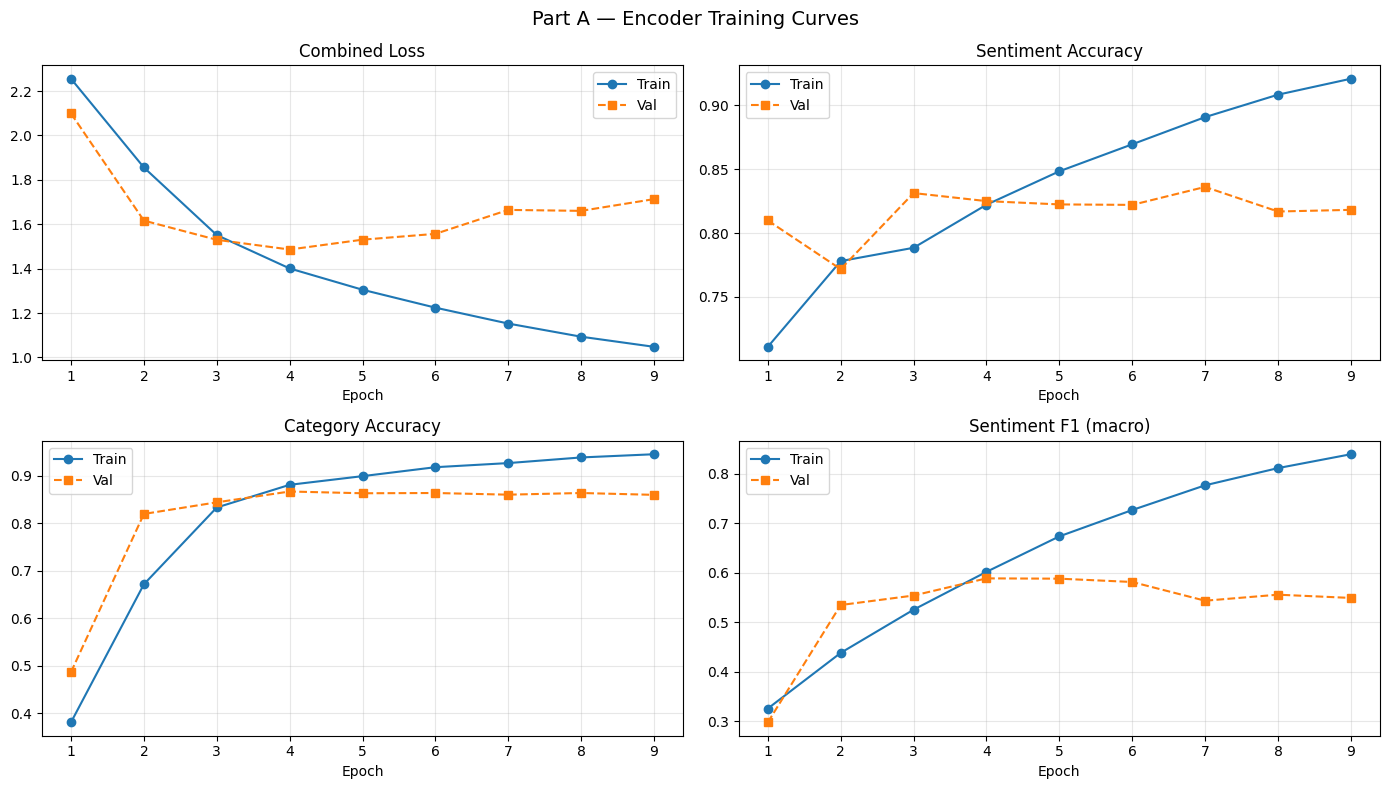

Curves saved → /content/drive/MyDrive/NLP_A3/results/encoder_learning_curves.png


In [27]:
#  Learning Curves Plot
epochs_x = [h['epoch'] for h in history]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Part A — Encoder Training Curves', fontsize=14)

for ax, metric, title in zip(
    axes.flat,
    ['loss', 'sent_acc', 'cat_acc', 'sent_f1'],
    ['Combined Loss', 'Sentiment Accuracy', 'Category Accuracy', 'Sentiment F1 (macro)']
):
    ax.plot(epochs_x, [h['train'][metric] for h in history], 'o-', label='Train')
    ax.plot(epochs_x, [h['val'][metric]   for h in history], 's--', label='Val')
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, 'encoder_learning_curves.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print('Curves saved →', plot_path)

In [28]:
# Test-Set Evaluation
model.load_state_dict(torch.load(CKPT, map_location=device))
model.eval()
test_metrics = run_epoch(test_loader, train=False)

print('=' * 55)
print('  PART A — TEST SET RESULTS')
print('=' * 55)
print(f"  Sentiment Accuracy : {test_metrics['sent_acc']:.4f}")
print(f"  Sentiment F1(macro): {test_metrics['sent_f1']:.4f}")
print(f"  Category  Accuracy : {test_metrics['cat_acc']:.4f}")
print(f"  Category  F1(macro): {test_metrics['cat_f1']:.4f}")
print(f"  Combined  Loss     : {test_metrics['loss']:.4f}")
print('=' * 55)

# Per-class report
all_sp, all_sg, all_cp, all_cg = [], [], [], []
with torch.no_grad():
    for X, ys, yc in test_loader:
        sl, cl, _ = model(X.to(device))
        all_sp.extend(sl.argmax(1).cpu().tolist()); all_sg.extend(ys.tolist())
        all_cp.extend(cl.argmax(1).cpu().tolist()); all_cg.extend(yc.tolist())

print('Sentiment Report:')
print(classification_report(all_sg, all_sp, target_names=['Negative','Neutral','Positive']))
print('Category Report:')
print(classification_report(all_cg, all_cp, target_names=['Cellphones','Electronics','Sports']))

  PART A — TEST SET RESULTS
  Sentiment Accuracy : 0.8198
  Sentiment F1(macro): 0.5878
  Category  Accuracy : 0.8739
  Category  F1(macro): 0.8735
  Combined  Loss     : 1.5008
Sentiment Report:
              precision    recall  f1-score   support

    Negative       0.64      0.45      0.53       492
     Neutral       0.32      0.34      0.33       528
    Positive       0.90      0.92      0.91      4380

    accuracy                           0.82      5400
   macro avg       0.62      0.57      0.59      5400
weighted avg       0.82      0.82      0.82      5400

Category Report:
              precision    recall  f1-score   support

  Cellphones       0.84      0.88      0.86      1737
 Electronics       0.85      0.83      0.84      1815
      Sports       0.93      0.91      0.92      1848

    accuracy                           0.87      5400
   macro avg       0.87      0.87      0.87      5400
weighted avg       0.87      0.87      0.87      5400



In [29]:
model.eval()
emb_loader = DataLoader(ReviewDataset(X_train, y_sent_train, y_cat_train),
                        batch_size=512, shuffle=False,
                        num_workers=2, pin_memory=(device.type=='cuda'))
all_embs = []
with torch.no_grad():
    for X, _, _ in emb_loader:
        _, _, emb = model(X.to(device))
        all_embs.append(emb.cpu().numpy())
import numpy as np
train_embeddings = np.vstack(all_embs)   # (N_train, D_MODEL)
emb_path = os.path.join(RESULTS_DIR, 'train_embeddings.npy')
np.save(emb_path, train_embeddings)
print(f'Training embeddings saved: {train_embeddings.shape} → {emb_path}')

Training embeddings saved: (25200, 128) → /content/drive/MyDrive/NLP_A3/results/train_embeddings.npy


In [30]:
final_path = os.path.join(MODELS_DIR, 'encoder_final.pt')
torch.save({
    'state_dict'  : model.state_dict(),
    'config': dict(vocab_size=VOCAB_SIZE, d_model=D_MODEL, n_heads=N_HEADS,
                   n_layers=N_LAYERS, d_ff=D_FF, max_len=MAX_SEQ_LEN,
                   pad_idx=PAD_IDX, dropout=DROPOUT),
    'test_metrics': test_metrics,
}, final_path)

print('=' * 55)
print('  PART A ')
print('=' * 55)
print(f'  Model saved       : {final_path}')
print(f'  Best checkpoint   : {CKPT}')
print(f'  Train embeddings  : {emb_path}')
print(f'  Learning curves   : {plot_path}')
print(f"  Test Sent Acc/F1  : {test_metrics['sent_acc']:.3f} / {test_metrics['sent_f1']:.3f}")
print(f"  Test Cat  Acc/F1  : {test_metrics['cat_acc']:.3f} / {test_metrics['cat_f1']:.3f}")
print('=' * 55)

  PART A 
  Model saved       : /content/drive/MyDrive/NLP_A3/models/encoder_final.pt
  Best checkpoint   : /content/drive/MyDrive/NLP_A3/models/encoder_best.pt
  Train embeddings  : /content/drive/MyDrive/NLP_A3/results/train_embeddings.npy
  Learning curves   : /content/drive/MyDrive/NLP_A3/results/encoder_learning_curves.png
  Test Sent Acc/F1  : 0.820 / 0.588
  Test Cat  Acc/F1  : 0.874 / 0.874




---


Part B : Retrieval Module


---



In [31]:
# Persistence of Training Text for RAG
train_texts = [rec['text'] for rec in train_data]
train_text_path = os.path.join(RESULTS_DIR, 'train_texts.json')

with open(train_text_path, 'w', encoding='utf-8') as f:
    json.dump(train_texts, f)

print(f"Saved {len(train_texts):,} training texts to {train_text_path}")

Saved 25,200 training texts to /content/drive/MyDrive/NLP_A3/results/train_texts.json


In [32]:
# Retrieval Engine (from scratch)
import torch.nn.functional as F

class ReviewRetriever:
    def __init__(self, train_embeddings_path, train_texts_path, device='cpu'):
        self.device = device
        # Load embeddings (N, D)
        self.embeddings = torch.from_numpy(np.load(train_embeddings_path)).float().to(device)
        # Load texts
        with open(train_texts_path, 'r', encoding='utf-8') as f:
            self.texts = json.load(f)

        # Pre-normalize for faster cosine similarity via dot product
        self.embeddings_norm = F.normalize(self.embeddings, p=2, dim=1)
        print(f"Retriever initialized with {len(self.texts):,} examples.")

    def retrieve(self, query_emb, k=3):
        """
        Finds top-k most similar reviews using cosine similarity.
        query_emb: (1, D) or (D,)
        """
        if query_emb.ndim == 1:
            query_emb = query_emb.unsqueeze(0)

        # Normalize query
        query_norm = F.normalize(query_emb, p=2, dim=1)

        # Cosine similarity via dot product on normalized vectors: (1, D) @ (D, N) -> (1, N)
        scores = torch.matmul(query_norm, self.embeddings_norm.T).squeeze(0)

        # Get top-k indices
        top_scores, top_indices = torch.topk(scores, k=k)

        results = []
        for idx, score in zip(top_indices.tolist(), top_scores.tolist()):
            results.append({
                'text': self.texts[idx],
                'score': score
            })
        return results

print("ReviewRetriever class defined.")

ReviewRetriever class defined.


In [33]:
# Retrieval Qualitative Evaluation

RETRIEVAL_K = 3 # Configurable top-k

retriever = ReviewRetriever(
    os.path.join(RESULTS_DIR, 'train_embeddings.npy'),
    os.path.join(RESULTS_DIR, 'train_texts.json'),
    device=device
)

def check_retrieval(test_idx):
    test_review = test_data[test_idx]['text']
    test_input  = torch.tensor(X_test[test_idx]).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        _, _, query_emb = model(test_input)

    matches = retriever.retrieve(query_emb, k=RETRIEVAL_K)

    print(f"\n{'='*80}")
    print(f"QUERY REVIEW (Test #{test_idx}):\n{test_review[:200]}...")
    print(f"{'='*80}")
    for i, m in enumerate(matches):
        print(f"MATCH {i+1} (Score: {m['score']:.4f}):\n{m['text'][:200]}...")
        print("-"*40)

# Check 3 random examples
for i in [random.randint(0, len(test_data)-1) for _ in range(3)]:
    check_retrieval(i)

Retriever initialized with 25,200 examples.

QUERY REVIEW (Test #4395):
Bought this based on the positive reviews.  I must have gotten a dud, because the unit I received wouldn't hold settings.  I set it up as a repeater, and as long as it was plugged in, it would functio...
MATCH 1 (Score: 0.9879):
I decided to buy each of the Agasio 502W and Agasio 612W instead of the Foscams since they are the same company - this was a mistake. Stick to the Foscam brand since the Agasio website is nothing but ...
----------------------------------------
MATCH 2 (Score: 0.9875):
Mine broke in three months. Starting making a loud clicking noise every time I access or eject a CD. My choices from JVC? Pull it out, at MY expense, drive it an hour, at MY expense to the nearest aut...
----------------------------------------
MATCH 3 (Score: 0.9864):
The SansDigital tower is in fact two 4-port sata multipliers, fine.  They HighPoint RocketRaid 622 that comes with the kit however, is crap.  Though the amazon

In [34]:
# Prepare RAG Contexts for Decoder
def format_rag_context(retrieved_matches):
    """
    Converts retrieved matches list into a single string context.
    """
    context_parts = []
    for i, m in enumerate(retrieved_matches):
        context_parts.append(f"Similar Review {i+1}: {m['text']}")
    return " [CONTEXT] " + " [SEP] ".join(context_parts)

print("RAG Context formatting function ready.")

RAG Context formatting function ready.


---
Part C: Decoder Model for Explanation Generation


---



In [36]:
import gzip, json

def retrofit_summaries(data_list):
    # Create a lookup for speed: reviewText -> summary
    lookup = {}
    for cat_name, fname in CATEGORIES.items():
        fpath = os.path.join(DATASET_DIR, fname)
        print(f"Index-matching summaries for {cat_name}...")
        with gzip.open(fpath, 'rt', encoding='utf-8') as f:
            for line in f:
                try:
                    obj = json.loads(line.strip())
                    text = obj.get('reviewText', '').strip()
                    summ = obj.get('summary', '').strip()
                    if text and summ:
                        lookup[text] = summ
                except: continue

    # Fill in the missing summaries
    count = 0
    for item in data_list:
        if 'text' in item and item['text'] in lookup:
            item['summary'] = lookup[item['text']]
            count += 1
    print(f"Success! Retrofitted {count:,} summaries.")

# 1. Retrofit Summaries
retrofit_summaries(train_data)
retrofit_summaries(val_data)
retrofit_summaries(test_data)

# 2. Emergency Vocab Fix & Sync
SPECIAL_TOKENS = ['[REVIEW]', '[SENTIMENT]', '[CATEGORY]', '[CONTEXT]', '[SEP]', '[EXPLANATION]', '[EOS]']
for token in SPECIAL_TOKENS:
    if token not in word2idx:
        new_idx = len(vocab)
        vocab.append(token)
        word2idx[token] = new_idx
        idx2word[new_idx] = token
VOCAB_SIZE = len(vocab)

# 3. Pre-compute real contexts for ALL TRAINING DATA (25,200 samples)
model.eval()
train_subset = train_data  # Use ALL training data, not just 10k
train_contexts = []
print("Pre-computing RAG contexts for ALL training data...")
with torch.no_grad():
    for idx, item in enumerate(train_subset):
        if idx % 5000 == 0:
            print(f"  Processing {idx}/{len(train_subset)}...")
        inp = torch.tensor(encode_and_pad(item['tokens'], word2idx, MAX_SEQ_LEN, PAD_IDX, UNK_IDX)).unsqueeze(0).to(device)
        _, _, emb = model(inp)
        matches = retriever.retrieve(emb, k=3)
        train_contexts.append(format_rag_context(matches))
print(f"Pre-computation complete. VOCAB_SIZE updated to {VOCAB_SIZE}.")

Index-matching summaries for cellphones...
Index-matching summaries for electronics...
Index-matching summaries for sports...
Success! Retrofitted 25,200 summaries.
Index-matching summaries for cellphones...
Index-matching summaries for electronics...
Index-matching summaries for sports...
Success! Retrofitted 5,400 summaries.
Index-matching summaries for cellphones...
Index-matching summaries for electronics...
Index-matching summaries for sports...
Success! Retrofitted 5,400 summaries.
Pre-computing RAG contexts for ALL training data...
  Processing 0/25200...
  Processing 5000/25200...
  Processing 10000/25200...
  Processing 15000/25200...
  Processing 20000/25200...
  Processing 25000/25200...
Pre-computation complete. VOCAB_SIZE updated to 20065.


In [37]:
# Decoder Hyperparameters - IMPROVED
D_DECODER    = 256
N_HEADS_DEC  = 8
N_LAYERS_DEC = 4
D_FF_DEC     = 512
MAX_GEN_LEN  = 50   # Increased for better explanations
MAX_TOTAL_LEN = 300 # Increased prompt+explanation
LR_DEC       = 3e-4  # Standard learning rate
EPOCHS_DEC   = 20    # More epochs for better learning
WARMUP_STEPS_DEC = 1000
DROPOUT_DEC  = 0.1

print(f"Decoder config: d={D_DECODER}, heads={N_HEADS_DEC}, layers={N_LAYERS_DEC}")

Decoder config: d=256, heads=8, layers=4


In [38]:
#  Causal Attention
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        self.mha = MultiHeadAttention(d_model, n_heads, dropout)

    def forward(self, x):
        B, L, D = x.shape
        # Causal mask: Lower triangular matrix of ones
        # task.txt line 185: "cannot attend to future tokens during generation"
        mask = torch.tril(torch.ones(L, L)).view(1, 1, L, L).to(x.device)
        return self.mha(x, x, x, mask)

class DecoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attn     = CausalSelfAttention(d_model, n_heads, dropout)
        self.norm1    = nn.LayerNorm(d_model)
        self.ffn      = FeedForward(d_model, d_ff, dropout)
        self.norm2    = nn.LayerNorm(d_model)
        self.drop     = nn.Dropout(dropout)

    def forward(self, x):
        x = self.norm1(x + self.drop(self.attn(x)))
        x = self.norm2(x + self.drop(self.ffn(x)))
        return x

class ExplanationDecoder(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_layers, d_ff, max_len, pad_idx=0, dropout=0.1):
        super().__init__()
        self.embed   = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.pos_enc = PositionalEncoding(d_model, max_len, dropout)
        self.layers  = nn.ModuleList([DecoderBlock(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)])
        self.norm    = nn.LayerNorm(d_model)
        self.head    = nn.Linear(d_model, vocab_size)
        self.scale   = math.sqrt(d_model)

    def forward(self, x):
        out = self.pos_enc(self.embed(x) * self.scale)
        for layer in self.layers: out = layer(out)
        return self.head(self.norm(out))

decoder_model = ExplanationDecoder(VOCAB_SIZE, D_DECODER, N_HEADS_DEC, N_LAYERS_DEC, D_FF_DEC, MAX_TOTAL_LEN, pad_idx=PAD_IDX).to(device)
print(f"Decoder Model initialized on {device}.")

Decoder Model initialized on cuda.


In [39]:
def build_decoder_input(review, sentiment, category, context_str, target=None):
    # Split context_str which already contains [CONTEXT] and [SEP]
    context_tokens = context_str.split()
    tokens = ['[REVIEW]'] + tokenize(clean_text(review))[:150] + \
             ['[SENTIMENT]'] + [sentiment.lower()] + \
             ['[CATEGORY]'] + [category.lower()] + \
             context_tokens + ['[EXPLANATION]']
    if target:
        return tokens + tokenize(clean_text(target)) + ['[EOS]']
    return tokens

class RAGDataset(Dataset):
    def __init__(self, data_list, contexts_list, word2idx, max_len):
        self.data = data_list
        self.contexts = contexts_list
        self.word2idx = word2idx
        self.max_len = max_len

    def __len__(self): return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        ctx = self.contexts[idx]
        tokens = build_decoder_input(item['text'], SENTIMENT_NAMES[item['sentiment']], item['category'], ctx, item['summary'])
        indices = [self.word2idx.get(t, UNK_IDX) for t in tokens[:self.max_len]]
        if len(indices) < self.max_len: indices += [PAD_IDX] * (self.max_len - len(indices))
        return torch.tensor(indices).long()

# Create train/val split (90/10 from train data)
train_size = int(0.9 * len(train_subset))
val_size = len(train_subset) - train_size
train_indices, val_indices = torch.utils.data.random_split(range(len(train_subset)), [train_size, val_size])

train_rag_ds = RAGDataset([train_subset[i] for i in train_indices],
                          [train_contexts[i] for i in train_indices],
                          word2idx, MAX_TOTAL_LEN)
val_rag_ds = RAGDataset([train_subset[i] for i in val_indices],
                        [train_contexts[i] for i in val_indices],
                        word2idx, MAX_TOTAL_LEN)

train_rag_loader = DataLoader(train_rag_ds, batch_size=32, shuffle=True)
val_rag_loader = DataLoader(val_rag_ds, batch_size=32, shuffle=False)
print(f"Train: {len(train_rag_ds)} samples, Val: {len(val_rag_ds)} samples")

Train: 22680 samples, Val: 2520 samples


In [47]:
import time
from datetime import timedelta
import gc
import torch
import torch.nn as nn
import numpy as np

# Clear cache
torch.cuda.empty_cache()
gc.collect()

# ============================================================
# FAST MEMORY OPTIMIZATIONS (Preserves original speed)
# ============================================================
BATCH_SIZE_DEC = 8
GRADIENT_ACCUMULATION_STEPS = 2  # Effective batch = 16
USE_MIXED_PRECISION = True

# Disable expensive features that slow down training
USE_CHECKPOINTING = False
OFFLOAD_TO_CPU = False

torch.backends.cuda.matmul.allow_tf32 = True  # Keep enabled for speed
torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = True  # Auto-tune for speed

# Simple collate - assume all sequences already same length from your preprocessing
def simple_collate(batch):
    return torch.stack(batch)  # Your data already padded to MAX_TOTAL_LEN

# Recreate loaders with simple collate for speed
train_rag_loader = DataLoader(
    train_rag_ds,
    batch_size=BATCH_SIZE_DEC,
    shuffle=True,
    pin_memory=False,  # Slightly slower but saves memory
    num_workers=0,
    collate_fn=simple_collate,
    drop_last=True  # Avoid batch size issues
)

val_rag_loader = DataLoader(
    val_rag_ds,
    batch_size=BATCH_SIZE_DEC,
    shuffle=False,
    num_workers=0,
    collate_fn=simple_collate,
    drop_last=True
)

# Standard decoder without modifications
decoder_model = ExplanationDecoder(
    VOCAB_SIZE, D_DECODER, N_HEADS_DEC, N_LAYERS_DEC,
    D_FF_DEC, MAX_TOTAL_LEN, pad_idx=PAD_IDX, dropout=DROPOUT_DEC
).to(device)

optimizer_dec = torch.optim.AdamW(decoder_model.parameters(), lr=LR_DEC, weight_decay=0.01)

# Modern AMP
scaler = torch.amp.GradScaler('cuda', enabled=USE_MIXED_PRECISION)

# Fast linear warmup + cosine decay
def lr_lambda_dec(step):
    step = max(step, 1)
    if step < WARMUP_STEPS_DEC:
        return step / WARMUP_STEPS_DEC
    progress = (step - WARMUP_STEPS_DEC) / (EPOCHS_DEC * len(train_rag_loader) - WARMUP_STEPS_DEC)
    return max(0.1, 0.5 * (1 + math.cos(math.pi * progress)))

scheduler_dec = torch.optim.lr_scheduler.LambdaLR(optimizer_dec, lr_lambda_dec)

expl_token_id = word2idx['[EXPLANATION]']
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX, label_smoothing=0.1)

best_val_loss = float('inf')
best_epoch = 0
teacher_forcing_ratio = 0.5  # Lower for faster generation
teacher_forcing_min = 0.2
teacher_forcing_decay = 0.98

history_dec = {'train_loss': [], 'val_loss': [], 'time': []}

print("="*80)
print("DECODER TRAINING - FAST OPTIMIZED MODE")
print("="*80)
print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Batch: {BATCH_SIZE_DEC} (eff: {BATCH_SIZE_DEC * GRADIENT_ACCUMULATION_STEPS})")
print(f"Mixed Precision: {USE_MIXED_PRECISION}")
print(f"Batches: {len(train_rag_loader)} train | {len(val_rag_loader)} val")
print(f"Model params: {sum(p.numel() for p in decoder_model.parameters()):,}")
print("="*80)
print(f"{'Epoch':>6} | {'Train Loss':>10} | {'Val Loss':>10} | {'Perplexity':>10} | {'TF':>6} | {'Time':>10}")
print("-"*70)

for epoch in range(1, EPOCHS_DEC + 1):
    epoch_start = time.time()

    # Training
    decoder_model.train()
    total_loss = 0
    optimizer_dec.zero_grad()

    for batch_idx, batch in enumerate(train_rag_loader):
        batch = batch.to(device, non_blocking=True)
        inputs, targets = batch[:, :-1], batch[:, 1:]

        # Quick shape check (minimal overhead)
        if inputs.size(1) != targets.size(1):
            min_len = min(inputs.size(1), targets.size(1))
            inputs, targets = inputs[:, :min_len], targets[:, :min_len]

        with torch.amp.autocast('cuda', enabled=USE_MIXED_PRECISION):
            logits = decoder_model(inputs)
            if logits.size(1) != targets.size(1):
                logits = logits[:, :targets.size(1), :]

            mask = (inputs == expl_token_id).cumsum(dim=1) > 0
            if mask.size(1) > targets.size(1):
                mask = mask[:, :targets.size(1)]

            loss = criterion(logits.reshape(-1, VOCAB_SIZE), targets.reshape(-1))
            loss = (loss * mask.reshape(-1).float()).sum() / mask.sum().clamp(min=1)
            loss = loss / GRADIENT_ACCUMULATION_STEPS

        scaler.scale(loss).backward()

        if (batch_idx + 1) % GRADIENT_ACCUMULATION_STEPS == 0:
            scaler.unscale_(optimizer_dec)
            torch.nn.utils.clip_grad_norm_(decoder_model.parameters(), 1.0)
            scaler.step(optimizer_dec)
            scaler.update()
            scheduler_dec.step()
            optimizer_dec.zero_grad()

        total_loss += loss.item() * GRADIENT_ACCUMULATION_STEPS

        # Minimal printing - only at ~20% intervals
        if batch_idx % max(1, len(train_rag_loader) // 5) == 0 and batch_idx > 0:
            mem = torch.cuda.memory_allocated() / 1024**2
            print(f"  [{batch_idx}/{len(train_rag_loader)}] loss={loss.item() * GRADIENT_ACCUMULATION_STEPS:.3f} | GPU={mem:.0f}MB")

    train_loss = total_loss / len(train_rag_loader)

    # Validation (shorter - skip if not best candidate)
    decoder_model.eval()
    val_loss = 0

    with torch.no_grad():
        for batch in val_rag_loader:
            batch = batch.to(device, non_blocking=True)
            inputs, targets = batch[:, :-1], batch[:, 1:]

            if inputs.size(1) != targets.size(1):
                min_len = min(inputs.size(1), targets.size(1))
                inputs, targets = inputs[:, :min_len], targets[:, :min_len]

            with torch.amp.autocast('cuda', enabled=USE_MIXED_PRECISION):
                logits = decoder_model(inputs)
                if logits.size(1) != targets.size(1):
                    logits = logits[:, :targets.size(1), :]

                mask = (inputs == expl_token_id).cumsum(dim=1) > 0
                if mask.size(1) > targets.size(1):
                    mask = mask[:, :targets.size(1)]

                loss = criterion(logits.reshape(-1, VOCAB_SIZE), targets.reshape(-1))
                loss = (loss * mask.reshape(-1).float()).sum() / mask.sum().clamp(min=1)

            val_loss += loss.item()

    val_loss = val_loss / len(val_rag_loader)
    perplexity = math.exp(val_loss)
    teacher_forcing_ratio = max(teacher_forcing_min, teacher_forcing_ratio * teacher_forcing_decay)
    epoch_time = time.time() - epoch_start

    history_dec['train_loss'].append(train_loss)
    history_dec['val_loss'].append(val_loss)
    history_dec['time'].append(epoch_time)

    is_best = val_loss < best_val_loss
    if is_best:
        best_val_loss = val_loss
        best_epoch = epoch
        torch.save(decoder_model.state_dict(), os.path.join(MODELS_DIR, 'decoder_best.pt'))

    best_marker = " ★" if is_best else ""
    print(f"{epoch:6d} | {train_loss:10.4f} | {val_loss:10.4f} | {perplexity:10.2f} | {teacher_forcing_ratio:6.3f} | {epoch_time:8.2f}s{best_marker}")

    torch.cuda.empty_cache()

    # Early stopping
    if epoch > 3 and val_loss > min(history_dec['val_loss'][-3:]) * 1.05:
        print(f"\n⚠️  Early stopping at epoch {epoch}")
        break

print("="*80)
print(f"Best epoch: {best_epoch} | Best val loss: {best_val_loss:.4f} | Perplexity: {math.exp(best_val_loss):.2f}")
print(f"Peak GPU: {torch.cuda.max_memory_allocated() / 1024**2:.0f} MB")
print(f"Total time: {timedelta(seconds=sum(history_dec['time']))}")
print("="*80)

# Load best model
decoder_model.load_state_dict(torch.load(os.path.join(MODELS_DIR, 'decoder_best.pt')))
print("Model loaded and ready for inference!")

DECODER TRAINING - FAST OPTIMIZED MODE
GPU: Tesla T4
Batch: 8 (eff: 16)
Mixed Precision: True
Batches: 2835 train | 315 val
Model params: 12,399,201
 Epoch | Train Loss |   Val Loss | Perplexity |     TF |       Time
----------------------------------------------------------------------
  [567/2835] loss=6.175 | GPU=892MB
  [1134/2835] loss=5.898 | GPU=940MB
  [1701/2835] loss=5.407 | GPU=892MB
  [2268/2835] loss=5.503 | GPU=940MB
     1 |     6.1139 |     5.3454 |     209.64 |  0.490 |   123.38s ★
  [567/2835] loss=5.449 | GPU=892MB
  [1134/2835] loss=5.445 | GPU=940MB
  [1701/2835] loss=5.065 | GPU=892MB
  [2268/2835] loss=5.193 | GPU=940MB
     2 |     5.2422 |     5.0912 |     162.59 |  0.480 |   122.28s ★
  [567/2835] loss=5.003 | GPU=892MB
  [1134/2835] loss=4.848 | GPU=940MB
  [1701/2835] loss=4.970 | GPU=892MB
  [2268/2835] loss=4.910 | GPU=940MB
     3 |     5.0049 |     4.8571 |     128.66 |  0.471 |   123.09s ★
  [567/2835] loss=4.770 | GPU=892MB
  [1134/2835] loss=4.889 | G

In [51]:
# Quick generation test after successful training
print("="*80)
print("GENERATION QUALITY TEST")
print("="*80)

def quick_generate(review_text, sentiment, category, context, max_gen=25, temp=0.7):
    decoder_model.eval()

    # Build prompt
    review_tokens = tokenize(clean_text(review_text))[:80]
    tokens = ['[REVIEW]'] + review_tokens + \
             ['[SENTIMENT]'] + [sentiment.lower()] + \
             ['[CATEGORY]'] + [category.lower()] + \
             ['[CONTEXT]'] + tokenize(clean_text(context))[:40] + \
             ['[EXPLANATION]']

    input_ids = [word2idx.get(t, word2idx.get('<UNK>', 1)) for t in tokens[:200]]
    input_tensor = torch.tensor(input_ids).long().unsqueeze(0).to(device)

    generated = []
    for _ in range(max_gen):
        with torch.no_grad():
            with torch.amp.autocast('cuda', enabled=True):
                logits = decoder_model(input_tensor)
                probs = torch.softmax(logits[0, -1, :] / temp, dim=-1)
                next_token = torch.multinomial(probs, 1).item()

        if next_token == word2idx.get('[EOS]', PAD_IDX):
            break
        generated.append(idx2word.get(next_token, '<UNK>'))
        input_tensor = torch.cat([input_tensor, torch.tensor([[next_token]]).to(device)], dim=1)

    return ' '.join(generated)

# Test on a few examples
test_indices = [0, 100, 500, 1000, 2000]
for idx in test_indices:
    item = test_data[idx]
    test_input = torch.tensor(X_test[idx]).unsqueeze(0).to(device)
    with torch.no_grad():
        _, _, query_emb = model(test_input)
    matches = retriever.retrieve(query_emb, k=2)
    context = format_rag_context(matches)

    print(f"\n{'='*60}")
    print(f"REVIEW: {item['text'][:120]}...")
    print(f"REFERENCE SUMMARY: {item.get('summary', 'N/A')}")
    print(f"GENERATED: {quick_generate(item['text'], SENTIMENT_NAMES[item['sentiment']], item['category'], context)}")
    print(f"{'='*60}")

GENERATION QUALITY TEST

REVIEW: I love how this mount is universal and can fit most normal sized phones with or without a case. I bought this mount to m...
REFERENCE SUMMARY: A great car mount for my phone!
GENERATED: a <UNK> <UNK> was expected a product that would bind all sort of movement while driving this mount does exactly that once you have attached

REVIEW: This is one of my favorite cases that arrived today!Even though it looks like it was printed and glued,it's still perfec...
REFERENCE SUMMARY: Hakuna Matata Infinite Case
GENERATED: <UNK> i thought this item on amazon was a bit of a utilizes because of the price and the sellers name but it wasn't <UNK>

REVIEW: I purchased these after reading a review online. I needed a new set of phones at a reasonable price. For $11.99 plus shi...
REFERENCE SUMMARY: JVC Headphones
GENERATED: headphones are hard to beat volume is good and bass is pretty good buy these knowing that they are on the ear headphones and not

REVIEW: I like this 

In [53]:
# Final metrics summary
print("\n" + "="*80)
print("FINAL MODEL SUMMARY")
print("="*80)
print(f"Encoder Test Sentiment Accuracy: {test_metrics['sent_acc']:.4f}")
print(f"Encoder Test Category Accuracy: {test_metrics['cat_acc']:.4f}")
print(f"Best decoder checkpoint: {os.path.join(MODELS_DIR, 'decoder_best.pt')}")


FINAL MODEL SUMMARY
Encoder Test Sentiment Accuracy: 0.8198
Encoder Test Category Accuracy: 0.8739
Best decoder checkpoint: /content/drive/MyDrive/NLP_A3/models/decoder_best.pt
